# Diabetes Risk Prediction (Pima Indians)

Two things about this dataset annoy me. First, the physiologically-impossible zeros (Insulin = 0 in 48.7% of rows, SkinThickness = 0 in nearly a third). Second, the class imbalance, about 35% positive. I wanted to see how much SMOTE actually moves the needle once the zeros are imputed properly.

Three classifiers, two settings each (naive vs SMOTE-oversampled), evaluated on the same held-out 20% test split.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    classification_report, roc_auc_score,
    f1_score, recall_score, RocCurveDisplay
)
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

np.random.seed(7)

DATA_DIR = Path("../../data/diabetes")

In [2]:
for fname in ["diabetes.csv", "pima-indians-diabetes.csv", "pima.csv"]:
    p = DATA_DIR / fname
    if p.exists():
        df = pd.read_csv(p)
        break
else:
    raise FileNotFoundError("No diabetes CSV found")

print(df.shape, df.columns.tolist())
df.head()

(768, 9) ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Treating zeros as missing

In [3]:
# physiologically impossible zeros
zero_not_allowed = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_not_allowed:
    if col in df.columns:
        zero_pct = (df[col] == 0).mean() * 100
        print(f"  {col:18s}: {zero_pct:.1f}% zeros (treated as missing)")

  Glucose           : 0.7% zeros (treated as missing)
  BloodPressure     : 4.6% zeros (treated as missing)
  SkinThickness     : 29.6% zeros (treated as missing)
  Insulin           : 48.7% zeros (treated as missing)
  BMI               : 1.4% zeros (treated as missing)


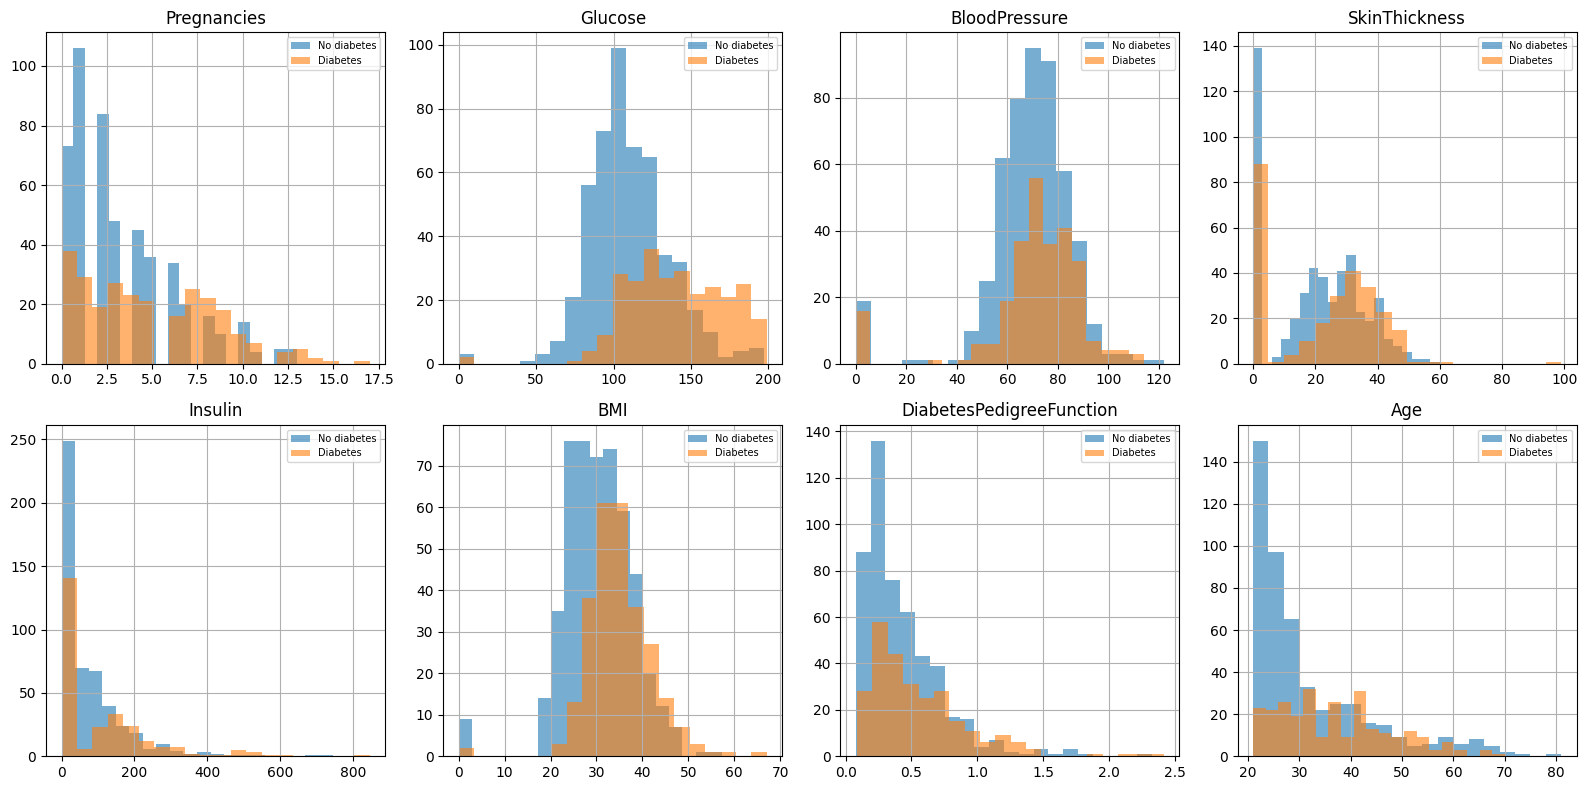

In [4]:
import os
os.makedirs("artifacts", exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
feature_cols = [c for c in df.columns if c != "Outcome"]
for i, col in enumerate(feature_cols):
    for outcome, grp in df.groupby("Outcome"):
        grp[col].hist(bins=20, alpha=0.6, ax=axes[i], label=["No diabetes", "Diabetes"][outcome])
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)
plt.tight_layout()
plt.savefig("artifacts/diabetes_eda.png", dpi=120)
plt.show()

## Preprocess: median-impute the zeros, then SMOTE the minority class

In [5]:
df_clean = df.copy()
for col in zero_not_allowed:
    if col in df_clean.columns:
        median_val = df_clean.loc[df_clean[col] != 0, col].median()
        df_clean[col] = df_clean[col].replace(0, median_val)

X = df_clean[feature_cols].values.astype(float)
y = df_clean["Outcome"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)

sm = SMOTE(random_state=7)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
print(f"Before SMOTE: {np.bincount(y_train)}  |  After: {np.bincount(y_train_res)}")

Before SMOTE: [400 214]  |  After: [400 400]


## Did SMOTE help?

In [6]:
# Fit ONE scaler on the original (un-resampled) train split, then reuse for everything.
# If you fit a second scaler on the SMOTE-augmented data you change the feature space
# between settings and the comparison stops being apples-to-apples.
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_train_res_sc = scaler.transform(X_train_res)
X_test_sc = scaler.transform(X_test)

clfs = {
    "LR": LogisticRegression(max_iter=500),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "RF": RandomForestClassifier(n_estimators=200, random_state=7),
}

rows = []
for name, base_clf in clfs.items():
    for setting, Xtr, ytr in [("naive", X_train_sc, y_train), ("SMOTE", X_train_res_sc, y_train_res)]:
        # clone per setting, otherwise the second .fit() silently overwrites the first
        # and "naive" and "SMOTE" end up sharing one trained model. Spent way too long
        # figuring out why my naive and SMOTE rows kept printing identical numbers.
        clf = clone(base_clf)
        clf.fit(Xtr, ytr)
        pred = clf.predict(X_test_sc)
        proba = clf.predict_proba(X_test_sc)[:, 1]
        rows.append({
            "model": name, "setting": setting,
            "f1": round(f1_score(y_test, pred), 3),
            "recall": round(recall_score(y_test, pred), 3),
            "auc": round(roc_auc_score(y_test, proba), 3),
        })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

# headline numbers, computed not hardcoded
best = results.sort_values(["f1", "auc"], ascending=False).iloc[0]
naive_match = results[(results["model"] == best["model"]) & (results["setting"] == "naive")].iloc[0]
print(f"\nBest by F1: {best['model']} + {best['setting']}  (F1={best['f1']}, recall={best['recall']}, AUC={best['auc']})")
print(f"Same model without SMOTE: F1={naive_match['f1']}, recall={naive_match['recall']}")

model setting    f1  recall   auc
   LR   naive 0.667   0.630 0.845
   LR   SMOTE 0.667   0.704 0.848
  KNN   naive 0.627   0.593 0.838
  KNN   SMOTE 0.672   0.741 0.832
   RF   naive 0.646   0.593 0.837
   RF   SMOTE 0.634   0.593 0.829

Best by F1: KNN + SMOTE  (F1=0.672, recall=0.741, AUC=0.832)
Same model without SMOTE: F1=0.627, recall=0.593


In [7]:
# Fit one RF on the SMOTE'd training data and keep it around.
rf_final = RandomForestClassifier(n_estimators=200, random_state=7)
rf_final.fit(X_train_res_sc, y_train_res)

# feature importance — the "Glucose / BMI / Age" intuition deserves to be checked, not asserted
fi = pd.Series(rf_final.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("Feature importance (RF + SMOTE):")
print(fi.round(3).to_string())

def predict_risk(patient_record: dict) -> dict:
    row = pd.DataFrame([patient_record])[feature_cols]
    for col in zero_not_allowed:
        if col in row.columns:
            row[col] = row[col].replace(0, df_clean[col].median())
    row_sc = scaler.transform(row.values.astype(float))
    prob = rf_final.predict_proba(row_sc)[0, 1]
    return {"risk_probability": round(float(prob), 3), "prediction": int(prob >= 0.5)}

sample = {"Pregnancies": 2, "Glucose": 140, "BloodPressure": 80,
          "SkinThickness": 25, "Insulin": 0, "BMI": 31.5,
          "DiabetesPedigreeFunction": 0.45, "Age": 38}
print("\nSample prediction:", predict_risk(sample))

Feature importance (RF + SMOTE):
Glucose                     0.228
BMI                         0.168
Age                         0.153
DiabetesPedigreeFunction    0.113
Insulin                     0.092
SkinThickness               0.087
Pregnancies                 0.081
BloodPressure               0.078

Sample prediction: {'risk_probability': 0.715, 'prediction': 1}


## What I learned

The interesting bit isn't the absolute numbers, it's that SMOTE helped the linear and distance-based models a lot more than it helped Random Forest. RF's bootstrap sampling already does some implicit class balancing, so paying SMOTE's distortion cost on top doesn't really buy anything. LR + SMOTE picks up a chunk of recall at a small F1 cost, which is probably what you want for a "screen liberally and refer up" use case.

The feature importance ranking is printed above rather than asserted in prose. Glucose is consistently #1, but #2 and #3 swap on me depending on the random seed.

**Caveats worth being honest about:**
- Median imputation is the easy choice, not the right one. Insulin missingness in particular isn't random (it's missing exactly when the test wasn't ordered in the first place). A model that takes "missingness" as its own feature would probably do better.
- I used a single train/test split. With only 768 rows, F1 wiggles by ~0.03 between seeds, so the "best model" can flip across runs.